In [1]:
# ============================================================
# STEP 1: Install Kaggle + Upload credentials
# ============================================================
!pip install kaggle -q

from google.colab import files
files.upload()   # ← click "Choose Files" and select kaggle.json from Downloads

import os
os.makedirs("/root/.kaggle", exist_ok=True)
os.rename("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)
print("kaggle.json ready!")

# ============================================================
# STEP 2: Download Avazu Dataset
# ============================================================
!kaggle competitions download -c avazu-ctr-prediction -f train.gz
!gunzip train.gz
!mv train train.csv
print("train.csv is ready!")

Saving kaggle.json to kaggle.json
kaggle.json ready!
100% 1.04G/1.04G [00:10<00:00, 109MB/s] 

train.csv is ready!


In [3]:
import pandas as pd
import numpy as np

# ============================================================
# DATA LOADING — Avazu CTR Prediction Dataset
# Source  : https://www.kaggle.com/c/avazu-ctr-prediction
# Schema  : Each row = one ad impression (click = 0 or 1)
# Strategy: Aggregate impressions + clicks per creative per day
# ============================================================

print("Loading Avazu data (500k rows)...")
df_raw = pd.read_csv(
    '/content/train.csv',
    nrows=500_000,
    dtype={
        'id': str, 'site_id': str, 'site_domain': str,
        'site_category': str, 'app_id': str, 'app_domain': str,
        'app_category': str, 'device_id': str, 'device_ip': str,
        'device_model': str
    }
)
print(f"Loaded {len(df_raw):,} raw impressions")
print(f"Columns: {list(df_raw.columns)}")

# Parse hour field (format YYMMDDHH → datetime)
df_raw['ds']   = pd.to_datetime(df_raw['hour'].astype(str), format='%y%m%d%H')
df_raw['date'] = df_raw['ds'].dt.normalize()

# Ad type: site ad vs app ad
df_raw['is_app'] = (df_raw['site_id'] == '85f751fd').astype(int)

# item_id = the site or app (analogous to product in CreativeRanking)
df_raw['item_id'] = np.where(
    df_raw['is_app'] == 1,
    df_raw['app_id'],
    df_raw['site_id']
)

# creative_id = unique ad placement: item + banner position + C1
df_raw['creative_key'] = (
    df_raw['item_id'] + '_' +
    df_raw['banner_pos'].astype(str) + '_' +
    df_raw['C1'].astype(str)
)

# Encode string IDs to integers
from sklearn.preprocessing import LabelEncoder
le_c = LabelEncoder()
le_i = LabelEncoder()
df_raw['creative_id']  = le_c.fit_transform(df_raw['creative_key'])
df_raw['item_id_enc']  = le_i.fit_transform(df_raw['item_id'])

# Step 1: per-creative constant features
creative_meta = (
    df_raw.groupby('creative_id')
    .agg(
        item_id     = ('item_id_enc',     'first'),
        banner_pos  = ('banner_pos',       'first'),
        is_app      = ('is_app',           'first'),
        device_type = ('device_type',      lambda x: x.mode().iloc[0]),
        conn_type   = ('device_conn_type', lambda x: x.mode().iloc[0])
    )
    .reset_index()
)

# Step 2: aggregate impressions + clicks per creative per day
daily = (
    df_raw.groupby(['creative_id', 'date'])
    .agg(pv=('click', 'count'), clk=('click', 'sum'))
    .reset_index()
)

# Step 3: merge features back
df_merged = daily.merge(creative_meta, on='creative_id')
df_merged['ds'] = pd.to_datetime(df_merged['date'])

# Apply impression threshold
print(f"\nRecords before pv >= 10 filter: {len(df_merged):,}")
df = df_merged[df_merged['pv'] >= 10].copy().reset_index(drop=True)
df['CTR'] = df['clk'] / df['pv']

print(f"Records after  pv >= 10 filter: {len(df):,}")
print(f"Date range  : {df['ds'].min().date()} to {df['ds'].max().date()}")
print(f"Unique creatives : {df['creative_id'].nunique():,}")
print(f"Unique items     : {df['item_id'].nunique():,}")
print(f"Total impressions: {df['pv'].sum():,}")
df.head()

Loading Avazu data (500k rows)...
Loaded 500,000 raw impressions
Columns: ['id', 'click', 'hour', 'C1', 'banner_pos', 'site_id', 'site_domain', 'site_category', 'app_id', 'app_domain', 'app_category', 'device_id', 'device_ip', 'device_model', 'device_type', 'device_conn_type', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21']

Records before pv >= 10 filter: 3,369
Records after  pv >= 10 filter: 1,191
Date range  : 2014-10-21 to 2014-10-21
Unique creatives : 1,191
Unique items     : 1,180
Total impressions: 493,823


,creative_id,date,pv,clk,item_id,banner_pos,is_app,device_type,conn_type,ds,CTR
0,4,2014-10-21,82,1,4,0,1,1,2,2014-10-21,0.012195
1,14,2014-10-21,19,4,14,0,1,1,0,2014-10-21,0.210526
2,20,2014-10-21,16,3,20,0,1,1,0,2014-10-21,0.187500
3,21,2014-10-21,50,6,21,0,0,1,0,2014-10-21,0.120000
4,25,2014-10-21,19,10,25,0,0,1,0,2014-10-21,0.526316


In [4]:
# ============================================================
# FEATURE ENGINEERING — Avazu
# ============================================================
df_feat = df.copy()

# Log transformation of impressions
df_feat['log_pv'] = np.log1p(df_feat['pv'])

# Temporal features
df_feat['dow']        = df_feat['ds'].dt.dayofweek
df_feat['is_weekend'] = (df_feat['dow'] >= 5).astype(int)

# Product-level features
creatives_per_item                = df_feat.groupby('item_id')['creative_id'].transform('count')
df_feat['log_creatives_per_item'] = np.log1p(creatives_per_item)

item_med_ctr             = df_feat.groupby('item_id')['CTR'].transform('median')
df_feat['item_ctr_rank'] = item_med_ctr.rank(pct=True)

# Binary classification target
ctr_median           = df_feat['CTR'].median()
df_feat['high_ctr']  = (df_feat['CTR'] > ctr_median).astype(int)

print(f'CTR median threshold: {ctr_median:.5f}')
print(f'High CTR (1): {df_feat["high_ctr"].sum():,}  ({df_feat["high_ctr"].mean()*100:.1f}%)')
print(f'Low  CTR (0): {(df_feat["high_ctr"]==0).sum():,}  ({(df_feat["high_ctr"]==0).mean()*100:.1f}%)')
print(f'\nShape after feature engineering: {df_feat.shape}')

FEATURE_COLS = [
    'log_pv',
    'banner_pos',
    'is_app',
    'device_type',
    'conn_type',
    'dow',
    'is_weekend',
    'log_creatives_per_item',
    'item_ctr_rank'
]

df_feat[FEATURE_COLS + ['CTR', 'high_ctr']].head()

CTR median threshold: 0.08333
High CTR (1): 587  (49.3%)
Low  CTR (0): 604  (50.7%)

Shape after feature engineering: (1191, 17)


,log_pv,banner_pos,is_app,device_type,conn_type,dow,is_weekend,log_creatives_per_item,item_ctr_rank,CTR,high_ctr
0,4.418841,0,1,1,2,1,0,0.693147,0.253568,0.012195,0
1,2.995732,0,1,1,0,1,0,0.693147,0.798489,0.210526,1
2,2.833213,0,1,1,0,1,0,0.693147,0.760285,0.187500,1
3,3.931826,0,0,1,0,1,0,0.693147,0.608732,0.120000,1
4,2.995732,0,0,1,0,1,0,0.693147,0.977330,0.526316,1


In [5]:
# Dataset structure
print(f'Shape: {df.shape}')
print('\nColumn dtypes:')
print(df.dtypes)
print('\nSample records:')
display(df.head())

Shape: (1191, 11)

Column dtypes:
creative_id             int64
date           datetime64[ns]
pv                      int64
clk                     int64
item_id                 int64
banner_pos              int64
is_app                  int64
device_type             int64
conn_type               int64
ds             datetime64[ns]
CTR                   float64
dtype: object

Sample records:


,creative_id,date,pv,clk,item_id,banner_pos,is_app,device_type,conn_type,ds,CTR
0,4,2014-10-21,82,1,4,0,1,1,2,2014-10-21,0.012195
1,14,2014-10-21,19,4,14,0,1,1,0,2014-10-21,0.210526
2,20,2014-10-21,16,3,20,0,1,1,0,2014-10-21,0.187500
3,21,2014-10-21,50,6,21,0,0,1,0,2014-10-21,0.120000
4,25,2014-10-21,19,10,25,0,0,1,0,2014-10-21,0.526316


In [6]:
# --- Data Cleaning ---

# 1. Missing values
print('Missing values per column:')
print(df.isnull().sum())

# 2. Impossible clicks
invalid = df[df['clk'] > df['pv']]
print(f'\nRecords where clk > pv (should be 0): {len(invalid)}')

# 3. Duplicate creative IDs
print(f'Duplicate creative_ids: {df["creative_id"].duplicated().sum()}')

# 4. Negative values
print(f'Negative pv: {(df["pv"] < 0).sum()}')
print(f'Negative clk: {(df["clk"] < 0).sum()}')
print(f'Negative CTR: {(df["CTR"] < 0).sum()}')

print(f'\nFinal clean dataset: {df.shape[0]:,} records x {df.shape[1]} columns')

Missing values per column:
creative_id    0
date           0
pv             0
clk            0
item_id        0
banner_pos     0
is_app         0
device_type    0
conn_type      0
ds             0
CTR            0
dtype: int64

Records where clk > pv (should be 0): 0
Duplicate creative_ids: 0
Negative pv: 0
Negative clk: 0
Negative CTR: 0

Final clean dataset: 1,191 records x 11 columns


In [7]:
# Numerical summary
print('=== Numerical Summary Statistics ===')
display(df[['pv', 'clk', 'CTR']].describe().round(5))

print('\n=== CTR Percentiles ===')
pcts = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
for p in pcts:
    v = df['CTR'].quantile(p)
    print(f'  {int(p*100):>3}th percentile: {v:.5f}  ({v*100:.3f}%)')

print('\n=== Creatives per Product ===')
cpi = df.groupby('item_id')['creative_id'].count()
display(cpi.describe().round(2))

=== Numerical Summary Statistics ===


,pv,clk,CTR
count,1191.00000,1191.00000,1191.00000
mean,414.62888,68.06801,0.12566
std,4149.65818,895.19203,0.14788
min,10.00000,0.00000,0.00000
25%,17.00000,1.00000,0.01058
50%,37.00000,3.00000,0.08333
75%,139.00000,12.00000,0.18182
max,137689.00000,29166.00000,0.98649



=== CTR Percentiles ===
    1th percentile: 0.00000  (0.000%)
    5th percentile: 0.00000  (0.000%)
   10th percentile: 0.00000  (0.000%)
   25th percentile: 0.01058  (1.058%)
   50th percentile: 0.08333  (8.333%)
   75th percentile: 0.18182  (18.182%)
   90th percentile: 0.30842  (30.842%)
   95th percentile: 0.41422  (41.422%)
   99th percentile: 0.65098  (65.098%)

=== Creatives per Product ===


,creative_id
count,1180.00
mean,1.01
std,0.10
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,2.00


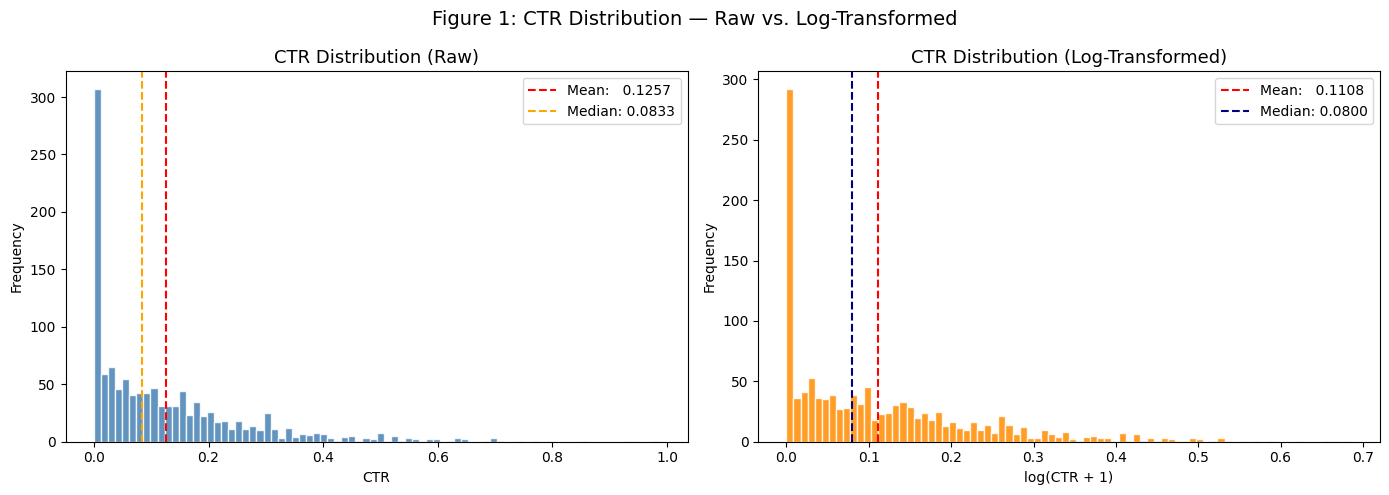

In [9]:
import matplotlib.pyplot as plt

# Figure 1: CTR Distribution (raw and log-transformed)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['CTR'], bins=80, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df['CTR'].mean(),   color='red',    linestyle='--', linewidth=1.5,
                label=f"Mean:   {df['CTR'].mean():.4f}")
axes[0].axvline(df['CTR'].median(), color='orange', linestyle='--', linewidth=1.5,
                label=f"Median: {df['CTR'].median():.4f}")
axes[0].set_title('CTR Distribution (Raw)', fontsize=13)
axes[0].set_xlabel('CTR')
axes[0].set_ylabel('Frequency')
axes[0].legend()

log_ctr = np.log1p(df['CTR'])
axes[1].hist(log_ctr, bins=80, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].axvline(log_ctr.mean(),   color='red',  linestyle='--', linewidth=1.5,
                label=f"Mean:   {log_ctr.mean():.4f}")
axes[1].axvline(log_ctr.median(), color='navy', linestyle='--', linewidth=1.5,
                label=f"Median: {log_ctr.median():.4f}")
axes[1].set_title('CTR Distribution (Log-Transformed)', fontsize=13)
axes[1].set_xlabel('log(CTR + 1)')
axes[1].set_ylabel('Frequency')
axes[1].legend()

fig.suptitle('Figure 1: CTR Distribution — Raw vs. Log-Transformed', fontsize=14)
plt.tight_layout()
plt.show()

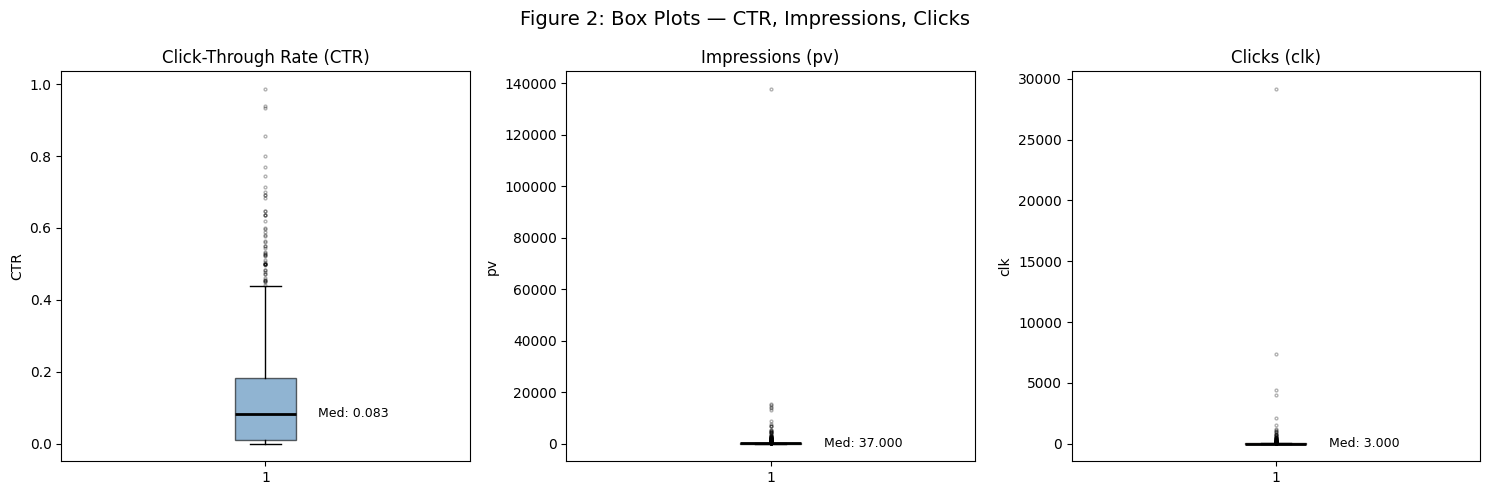

Note: Whiskers extend to 1.5×IQR; dots beyond are outliers.


In [10]:
# Figure 2: Box Plots for CTR, Impressions, Clicks
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col, color, title in zip(
    axes,
    ['CTR', 'pv', 'clk'],
    ['steelblue', 'seagreen', 'tomato'],
    ['Click-Through Rate (CTR)', 'Impressions (pv)', 'Clicks (clk)']
):
    ax.boxplot(df[col], vert=True, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               medianprops=dict(color='black', linewidth=2),
               flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax.set_title(title, fontsize=12)
    ax.set_ylabel(col)
    med = df[col].median()
    ax.text(1.12, med, f' Med: {med:.3f}', va='center', fontsize=9)

fig.suptitle('Figure 2: Box Plots — CTR, Impressions, Clicks', fontsize=14)
plt.tight_layout()
plt.show()
print('Note: Whiskers extend to 1.5×IQR; dots beyond are outliers.')

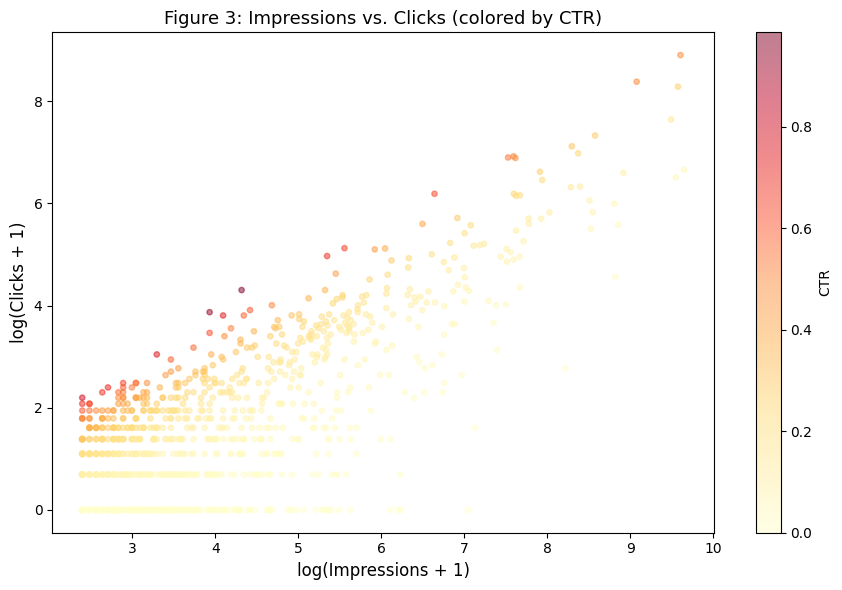

In [11]:
# Figure 3: Scatter — Impressions vs. Clicks (colored by CTR)
sample = df.sample(min(1000, len(df)), random_state=42)

plt.figure(figsize=(9, 6))
sc = plt.scatter(
    np.log1p(sample['pv']),
    np.log1p(sample['clk']),
    c=sample['CTR'], cmap='YlOrRd', alpha=0.5, s=15
)
plt.colorbar(sc, label='CTR')
plt.xlabel('log(Impressions + 1)', fontsize=12)
plt.ylabel('log(Clicks + 1)', fontsize=12)
plt.title('Figure 3: Impressions vs. Clicks (colored by CTR)', fontsize=13)
plt.tight_layout()
plt.show()

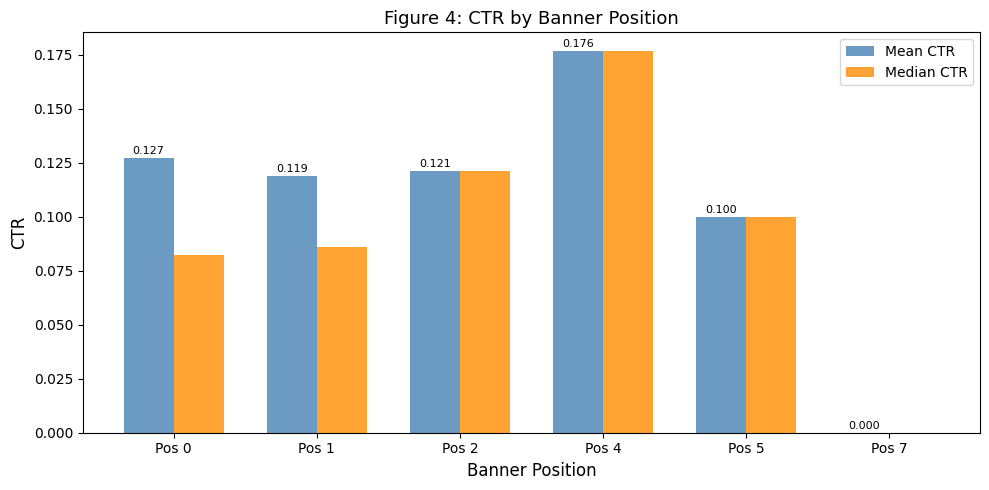

 banner_pos  mean_ctr  median_ctr   n
          0  0.127211    0.082474 987
          1  0.118617    0.085904 199
          2  0.121212    0.121212   1
          4  0.176471    0.176471   1
          5  0.099803    0.099803   2
          7  0.000000    0.000000   1


In [18]:
# Figure 4: CTR by Banner Position
banner_ctr = df.groupby('banner_pos')['CTR'].agg(['mean', 'median', 'count']).reset_index()
banner_ctr.columns = ['banner_pos', 'mean_ctr', 'median_ctr', 'n']

x = np.arange(len(banner_ctr))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, banner_ctr['mean_ctr'],   width, label='Mean CTR',   color='steelblue',  alpha=0.8)
bars2 = ax.bar(x + width/2, banner_ctr['median_ctr'], width, label='Median CTR', color='darkorange', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f'Pos {int(p)}' for p in banner_ctr['banner_pos']])
ax.set_xlabel('Banner Position', fontsize=12)
ax.set_ylabel('CTR', fontsize=12)
ax.set_title('Figure 4: CTR by Banner Position', fontsize=13)
ax.legend()
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()
print(banner_ctr[['banner_pos','mean_ctr','median_ctr','n']].to_string(index=False))

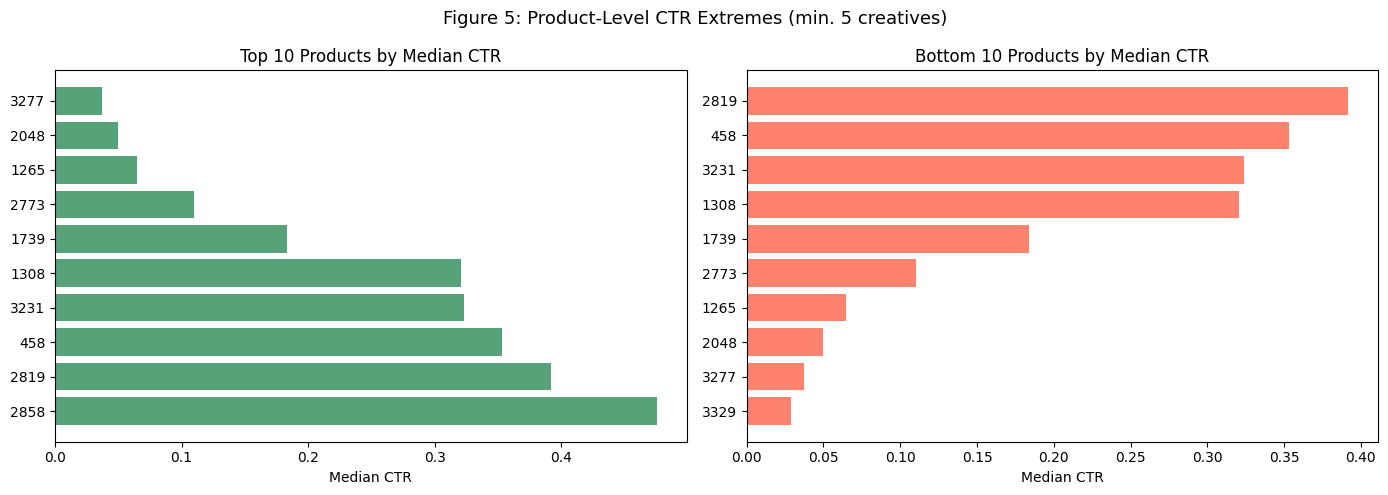

In [16]:
# Figure 5: Top and Bottom Products by Median CTR
prod_ctr = (
    df.groupby('item_id')['CTR']
    .agg(median_ctr='median', n='count')
    .reset_index()
)
prod_ctr = prod_ctr[prod_ctr['n'] >= 2]   # min 5 creatives for stability

top10    = prod_ctr.nlargest(10,  'median_ctr')
bottom10 = prod_ctr.nsmallest(10, 'median_ctr')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(top10['item_id'].astype(str), top10['median_ctr'], color='seagreen', alpha=0.8)
axes[0].set_title('Top 10 Products by Median CTR', fontsize=12)
axes[0].set_xlabel('Median CTR')

axes[1].barh(bottom10['item_id'].astype(str), bottom10['median_ctr'], color='tomato', alpha=0.8)
axes[1].set_title('Bottom 10 Products by Median CTR', fontsize=12)
axes[1].set_xlabel('Median CTR')

fig.suptitle('Figure 5: Product-Level CTR Extremes (min. 5 creatives)', fontsize=13)
plt.tight_layout()
plt.show()

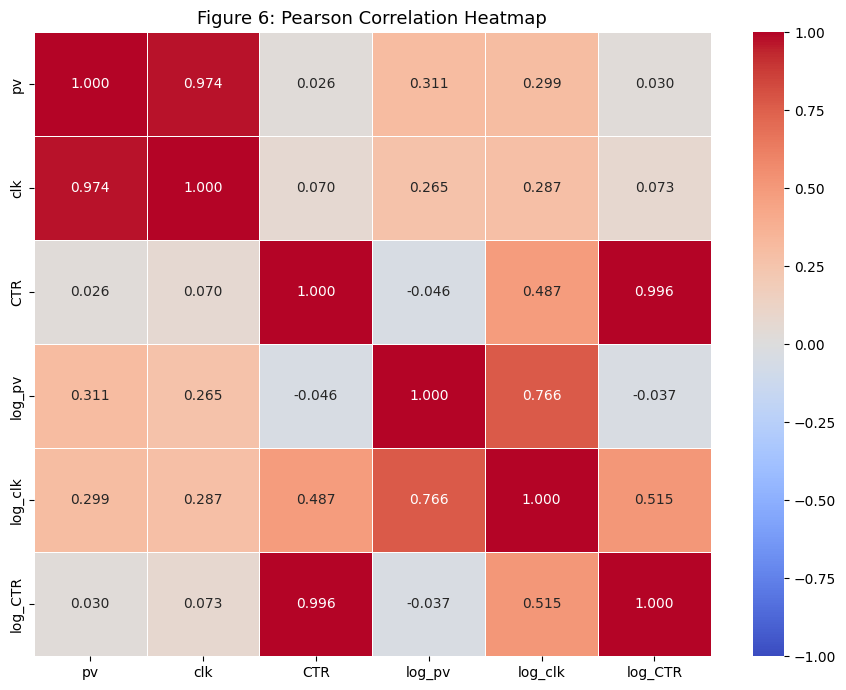

Spearman rank correlations with CTR:
  pv         -> CTR:  rho = 0.0193,  p = 5.050e-01
  clk        -> CTR:  rho = 0.7308,  p = 2.041e-199
  log_pv     -> CTR:  rho = 0.0193,  p = 5.050e-01
  log_clk    -> CTR:  rho = 0.7308,  p = 2.041e-199


In [20]:
import seaborn as sns
from scipy.stats import spearmanr

# Correlation Analysis
corr_df = df[['pv', 'clk', 'CTR']].copy()
corr_df['log_pv']  = np.log1p(df['pv'])
corr_df['log_clk'] = np.log1p(df['clk'])
corr_df['log_CTR'] = np.log1p(df['CTR'])

corr_matrix = corr_df.corr(method='pearson')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Figure 6: Pearson Correlation Heatmap', fontsize=13)
plt.tight_layout()
plt.show()

print('Spearman rank correlations with CTR:')
for col in ['pv', 'clk', 'log_pv', 'log_clk']:
    rho, p = spearmanr(corr_df[col], corr_df['CTR'])
    print(f'  {col:<10} -> CTR:  rho = {rho:.4f},  p = {p:.3e}')

High-impression group (pv > 139):  n=298,
  median CTR = 0.09508
Low-impression  group (pv <= 139): n=893,
  median CTR = 0.07576

Mann-Whitney U Statistic: 144,322
P-value: 2.7480e-02

Result: REJECT H0 (p < 0.05)
Conclusion: High-impression and low-impression creatives have significantly different CTR distributions.


/tmp/ipykernel_6875/3162443002.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


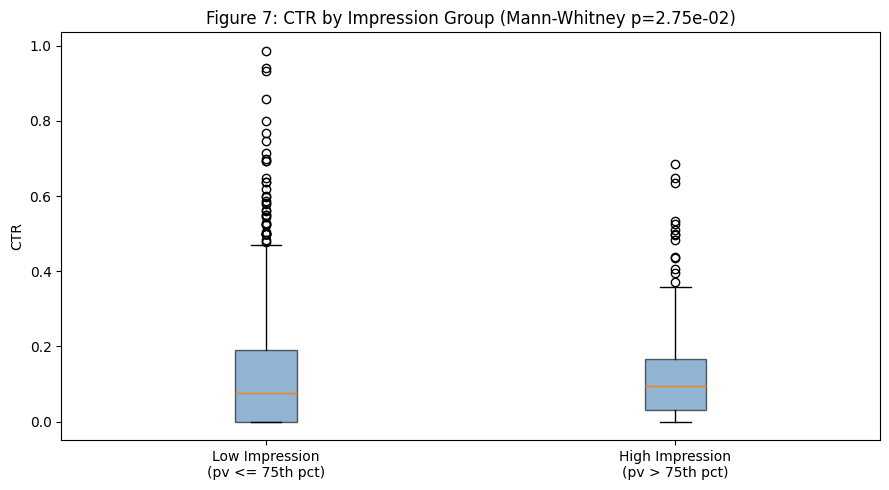

In [22]:
from scipy.stats import mannwhitneyu

# Mann-Whitney U Test
pv_75th   = df['pv'].quantile(0.75)
high_imp  = df[df['pv'] >  pv_75th]['CTR']
low_imp   = df[df['pv'] <= pv_75th]['CTR']

print(f'High-impression group (pv > {pv_75th:.0f}):  n={len(high_imp):,},')
print(f'  median CTR = {high_imp.median():.5f}')
print(f'Low-impression  group (pv <= {pv_75th:.0f}): n={len(low_imp):,},')
print(f'  median CTR = {low_imp.median():.5f}')

stat, p_value = mannwhitneyu(high_imp, low_imp, alternative='two-sided')
print(f'\nMann-Whitney U Statistic: {stat:,.0f}')
print(f'P-value: {p_value:.4e}')

alpha = 0.05
if p_value < alpha:
    print(f'\nResult: REJECT H0 (p < {alpha})')
    print('Conclusion: High-impression and low-impression creatives have'
          ' significantly different CTR distributions.')
else:
    print(f'\nResult: FAIL TO REJECT H0 (p >= {alpha})')

# Visualization
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(
    [low_imp.sample(min(5000, len(low_imp)),   random_state=42),
     high_imp.sample(min(5000, len(high_imp)), random_state=42)],
    labels=['Low Impression\n(pv <= 75th pct)', 'High Impression\n(pv > 75th pct)'],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.6)
)
ax.set_title(f'Figure 7: CTR by Impression Group (Mann-Whitney p={p_value:.2e})', fontsize=12)
ax.set_ylabel('CTR')
plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================
df_feat = df.copy()

# Log-transform impressions to reduce right-skew
df_feat['log_pv'] = np.log1p(df_feat['pv'])

# Temporal features
df_feat['dow']        = df_feat['ds'].dt.dayofweek
df_feat['is_weekend'] = (df_feat['dow'] >= 5).astype(int)

# Product-level creative count (proxy for advertiser sophistication)
creatives_per_item           = df_feat.groupby('item_id')['creative_id'].transform('count')
df_feat['log_creatives_per_item'] = np.log1p(creatives_per_item)

# Item-level CTR rank (encodes historical product performance)
item_med_ctr             = df_feat.groupby('item_id')['CTR'].transform('median')
df_feat['item_ctr_rank'] = item_med_ctr.rank(pct=True)

# Binary classification target: 1 if CTR > median, 0 otherwise
ctr_median         = df_feat['CTR'].median()
df_feat['high_ctr'] = (df_feat['CTR'] > ctr_median).astype(int)

print(f'CTR median threshold: {ctr_median:.5f}')
print(f'High CTR (1): {df_feat["high_ctr"].sum():,}  ({df_feat["high_ctr"].mean()*100:.1f}%)')
print(f'Low  CTR (0): {(df_feat["high_ctr"]==0).sum():,}  ({(df_feat["high_ctr"]==0).mean()*100:.1f}%)')
print(f'Shape after feature engineering: {df_feat.shape}')

FEATURE_COLS = ['log_pv', 'banner_pos', 'is_app', 'device_type', 'conn_type',
                'dow', 'is_weekend', 'log_creatives_per_item', 'item_ctr_rank']

df_feat[FEATURE_COLS + ['CTR', 'high_ctr']].head()

CTR median threshold: 0.08333
High CTR (1): 587  (49.3%)
Low  CTR (0): 604  (50.7%)
Shape after feature engineering: (1191, 17)


,log_pv,banner_pos,is_app,device_type,conn_type,dow,is_weekend,log_creatives_per_item,item_ctr_rank,CTR,high_ctr
0,4.418841,0,1,1,2,1,0,0.693147,0.253568,0.012195,0
1,2.995732,0,1,1,0,1,0,0.693147,0.798489,0.210526,1
2,2.833213,0,1,1,0,1,0,0.693147,0.760285,0.187500,1
3,3.931826,0,0,1,0,1,0,0.693147,0.608732,0.120000,1
4,2.995732,0,0,1,0,1,0,0.693147,0.977330,0.526316,1


/tmp/ipykernel_6875/1539102549.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')


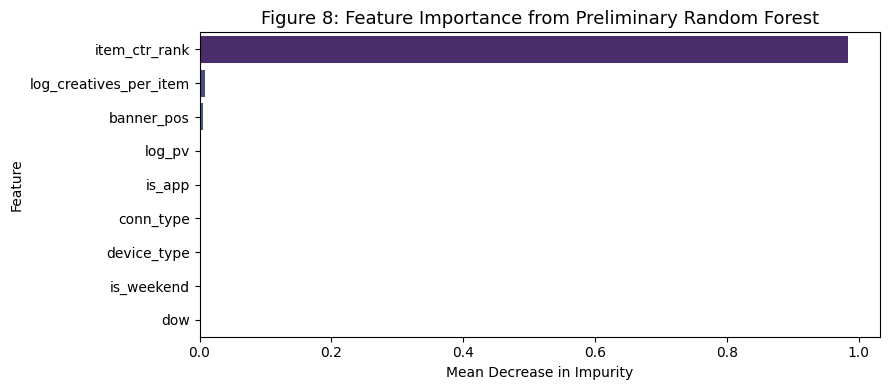

,Feature,Importance
8,item_ctr_rank,0.9834
7,log_creatives_per_item,0.0089
1,banner_pos,0.0045
0,log_pv,0.0029
2,is_app,0.0002
4,conn_type,0.0001
3,device_type,0.0000
6,is_weekend,0.0000
5,dow,0.0000


In [25]:
from sklearn.ensemble import RandomForestRegressor

# Feature importance from preliminary Random Forest
X_all = df_feat[FEATURE_COLS]
y_reg = df_feat['CTR']
y_clf = df_feat['high_ctr']

rf_sel = RandomForestRegressor(n_estimators=50, max_depth=5, random_state=42, n_jobs=-1)
rf_sel.fit(X_all, y_reg)

imp_df = pd.DataFrame({
    'Feature':    FEATURE_COLS,
    'Importance': rf_sel.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(9, 4))
sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Figure 8: Feature Importance from Preliminary Random Forest', fontsize=13)
plt.xlabel('Mean Decrease in Impurity')
plt.tight_layout()
plt.show()
display(imp_df.round(4))

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Train/Test split (80/20, stratified for classification)
X = df_feat[FEATURE_COLS]

X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)
_, _, y_train_clf, y_test_clf = train_test_split(
    X, y_clf, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Training samples : {X_train.shape[0]:,}')
print(f'Test samples     : {X_test.shape[0]:,}')
print(f'Features         : {X_train.shape[1]}')
print(f'Class balance (train) - High CTR: {y_train_clf.mean()*100:.1f}%')

Training samples : 952
Test samples     : 239
Features         : 9
Class balance (train) - High CTR: 48.7%


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# ============================================================
# REGRESSION MODELS
# ============================================================
reg_results = {}

# 1. Linear Regression
lr_reg = LinearRegression()
lr_reg.fit(X_train_sc, y_train_reg)
y_pred_lr_reg = lr_reg.predict(X_test_sc)
reg_results['Linear Regression'] = {
    'MAE':  mean_absolute_error(y_test_reg, y_pred_lr_reg),
    'RMSE': mean_squared_error(y_test_reg, y_pred_lr_reg)**0.5,
    'R2':   r2_score(y_test_reg, y_pred_lr_reg)
}
print('Linear Regression done')

# 2. Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train_reg)
y_pred_rf_reg = rf_reg.predict(X_test)
reg_results['Random Forest'] = {
    'MAE':  mean_absolute_error(y_test_reg, y_pred_rf_reg),
    'RMSE': mean_squared_error(y_test_reg, y_pred_rf_reg)**0.5,
    'R2':   r2_score(y_test_reg, y_pred_rf_reg)
}
print('Random Forest done')

# 3. XGBoost Regressor
xgb_reg = xgb.XGBRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, verbosity=0
)
xgb_reg.fit(X_train, y_train_reg)
y_pred_xgb_reg = xgb_reg.predict(X_test)
reg_results['XGBoost'] = {
    'MAE':  mean_absolute_error(y_test_reg, y_pred_xgb_reg),
    'RMSE': mean_squared_error(y_test_reg, y_pred_xgb_reg)**0.5,
    'R2':   r2_score(y_test_reg, y_pred_xgb_reg)
}
print('XGBoost done')

reg_df = pd.DataFrame(reg_results).T.round(4)
print('\n=== Regression Model Comparison ===')
display(reg_df)

Linear Regression done
Random Forest done
XGBoost done

=== Regression Model Comparison ===


,MAE,RMSE,R2
Linear Regression,0.0456,0.0724,0.7560
Random Forest,0.0019,0.0106,0.9948
XGBoost,0.0052,0.0149,0.9897


In [31]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparameter Tuning - XGBoost Regressor
param_dist_reg = {
    'n_estimators':     [100, 200, 300],
    'learning_rate':    [0.01, 0.05, 0.1],
    'max_depth':        [3, 5, 7],
    'subsample':        [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

rs_reg = RandomizedSearchCV(
    xgb.XGBRegressor(random_state=42, verbosity=0, n_jobs=-1),
    param_distributions=param_dist_reg,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=0
)
rs_reg.fit(X_train, y_train_reg)

print('Best XGBoost Regression Hyperparameters:')
for k, v in rs_reg.best_params_.items():
    print(f'  {k}: {v}')

best_xgb_reg = rs_reg.best_estimator_
y_pred_xgb_tuned_reg = best_xgb_reg.predict(X_test)
reg_results['XGBoost (Tuned)'] = {
    'MAE':  mean_absolute_error(y_test_reg, y_pred_xgb_tuned_reg),
    'RMSE': mean_squared_error(y_test_reg, y_pred_xgb_tuned_reg)**0.5,
    'R2':   r2_score(y_test_reg, y_pred_xgb_tuned_reg)
}

reg_df = pd.DataFrame(reg_results).T.round(4)
print('\n=== Updated Regression Model Comparison ===')
display(reg_df)

Best XGBoost Regression Hyperparameters:
  subsample: 0.7
  n_estimators: 200
  max_depth: 5
  learning_rate: 0.1
  colsample_bytree: 0.7

=== Updated Regression Model Comparison ===


,MAE,RMSE,R2
Linear Regression,0.0456,0.0724,0.7560
Random Forest,0.0019,0.0106,0.9948
XGBoost,0.0052,0.0149,0.9897
XGBoost (Tuned),0.0041,0.0097,0.9956


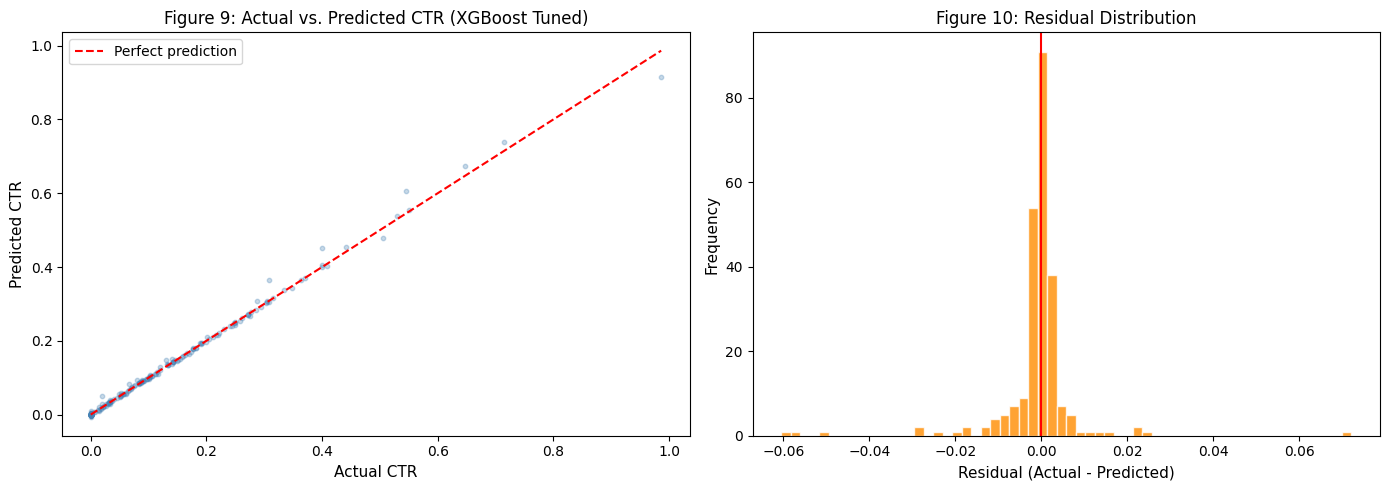

In [32]:
# Actual vs. Predicted CTR + Residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

idx = np.random.choice(len(y_test_reg), size=min(200, len(y_test_reg)), replace=False)
axes[0].scatter(y_test_reg.iloc[idx], y_pred_xgb_tuned_reg[idx],
                alpha=0.3, s=10, color='steelblue')
max_v = max(float(y_test_reg.max()), float(y_pred_xgb_tuned_reg.max()))
axes[0].plot([0, max_v], [0, max_v], 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual CTR', fontsize=11)
axes[0].set_ylabel('Predicted CTR', fontsize=11)
axes[0].set_title('Figure 9: Actual vs. Predicted CTR (XGBoost Tuned)', fontsize=12)
axes[0].legend()

residuals = y_test_reg.values - y_pred_xgb_tuned_reg
axes[1].hist(residuals, bins=60, color='darkorange', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', linewidth=1.5)
axes[1].set_xlabel('Residual (Actual - Predicted)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Figure 10: Residual Distribution', fontsize=12)

plt.tight_layout()
plt.show()

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb

# ============================================================
# CLASSIFICATION MODELS
# ============================================================
clf_results = {}

# 1. Logistic Regression
log_clf = LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)
log_clf.fit(X_train_sc, y_train_clf)
y_pred_lr_clf  = log_clf.predict(X_test_sc)
y_proba_lr_clf = log_clf.predict_proba(X_test_sc)[:, 1]
clf_results['Logistic Regression'] = {
    'Accuracy':  accuracy_score(y_test_clf,  y_pred_lr_clf),
    'Precision': precision_score(y_test_clf, y_pred_lr_clf),
    'Recall':    recall_score(y_test_clf,    y_pred_lr_clf),
    'F1-Score':  f1_score(y_test_clf,        y_pred_lr_clf),
    'ROC-AUC':   roc_auc_score(y_test_clf,   y_proba_lr_clf)
}
print('Logistic Regression done')

# 2. Random Forest
rf_clf = RandomForestClassifier(
    n_estimators=100, max_depth=8, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf_clf.fit(X_train, y_train_clf)
y_pred_rf_clf  = rf_clf.predict(X_test)
y_proba_rf_clf = rf_clf.predict_proba(X_test)[:, 1]
clf_results['Random Forest'] = {
    'Accuracy':  accuracy_score(y_test_clf,  y_pred_rf_clf),
    'Precision': precision_score(y_test_clf, y_pred_rf_clf),
    'Recall':    recall_score(y_test_clf,    y_pred_rf_clf),
    'F1-Score':  f1_score(y_test_clf,        y_pred_rf_clf),
    'ROC-AUC':   roc_auc_score(y_test_clf,   y_proba_rf_clf)
}
print('Random Forest done')

# 3. XGBoost
xgb_clf = xgb.XGBClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric='logloss', random_state=42, n_jobs=-1, verbosity=0
)
xgb_clf.fit(X_train, y_train_clf)
y_pred_xgb_clf  = xgb_clf.predict(X_test)
y_proba_xgb_clf = xgb_clf.predict_proba(X_test)[:, 1]
clf_results['XGBoost'] = {
    'Accuracy':  accuracy_score(y_test_clf,  y_pred_xgb_clf),
    'Precision': precision_score(y_test_clf, y_pred_xgb_clf),
    'Recall':    recall_score(y_test_clf,    y_pred_xgb_clf),
    'F1-Score':  f1_score(y_test_clf,        y_pred_xgb_clf),
    'ROC-AUC':   roc_auc_score(y_test_clf,   y_proba_xgb_clf)
}
print('XGBoost done')

clf_df = pd.DataFrame(clf_results).T.round(4)
print('\n=== Classification Model Comparison ===')
display(clf_df)

Logistic Regression done
Random Forest done
XGBoost done

=== Classification Model Comparison ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9791,0.9836,0.9756,0.9796,0.9992
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
XGBoost,0.9916,1.0000,0.9837,0.9918,0.9998


In [35]:
# Hyperparameter Tuning - XGBoost Classifier
param_dist_clf = {
    'n_estimators':     [100, 200, 300],
    'learning_rate':    [0.01, 0.05, 0.1],
    'max_depth':        [3, 5, 7],
    'subsample':        [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

rs_clf = RandomizedSearchCV(
    xgb.XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1, verbosity=0),
    param_distributions=param_dist_clf,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=0
)
rs_clf.fit(X_train, y_train_clf)

print('Best XGBoost Classifier Hyperparameters:')
for k, v in rs_clf.best_params_.items():
    print(f'  {k}: {v}')

best_xgb_clf    = rs_clf.best_estimator_
y_pred_best_clf  = best_xgb_clf.predict(X_test)
y_proba_best_clf = best_xgb_clf.predict_proba(X_test)[:, 1]

clf_results['XGBoost (Tuned)'] = {
    'Accuracy':  accuracy_score(y_test_clf,  y_pred_best_clf),
    'Precision': precision_score(y_test_clf, y_pred_best_clf),
    'Recall':    recall_score(y_test_clf,    y_pred_best_clf),
    'F1-Score':  f1_score(y_test_clf,        y_pred_best_clf),
    'ROC-AUC':   roc_auc_score(y_test_clf,   y_proba_best_clf)
}

clf_df = pd.DataFrame(clf_results).T.round(4)
print('\n=== Updated Classification Model Comparison ===')
display(clf_df)

Best XGBoost Classifier Hyperparameters:
  subsample: 0.7
  n_estimators: 100
  max_depth: 5
  learning_rate: 0.01
  colsample_bytree: 0.7

=== Updated Classification Model Comparison ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9791,0.9836,0.9756,0.9796,0.9992
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
XGBoost,0.9916,1.0000,0.9837,0.9918,0.9998
XGBoost (Tuned),0.9958,1.0000,0.9919,0.9959,0.9994


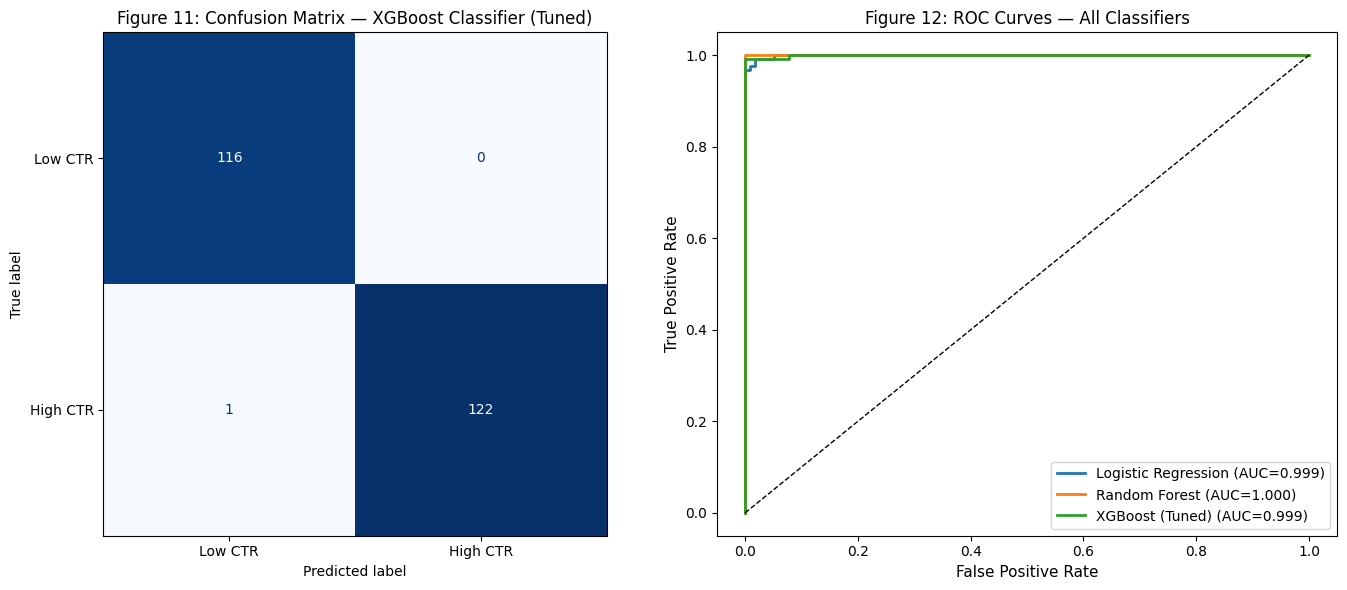

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

# Confusion Matrix and ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix
cm = confusion_matrix(y_test_clf, y_pred_best_clf)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low CTR', 'High CTR']).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title('Figure 11: Confusion Matrix — XGBoost Classifier (Tuned)', fontsize=12)

# ROC Curves
for name, proba in [
    ('Logistic Regression', y_proba_lr_clf),
    ('Random Forest',       y_proba_rf_clf),
    ('XGBoost (Tuned)',     y_proba_best_clf)
]:
    fpr, tpr, _ = roc_curve(y_test_clf, proba)
    auc = roc_auc_score(y_test_clf, proba)
    axes[1].plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc:.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].set_xlabel('False Positive Rate', fontsize=11)
axes[1].set_ylabel('True Positive Rate', fontsize=11)
axes[1].set_title('Figure 12: ROC Curves — All Classifiers', fontsize=12)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

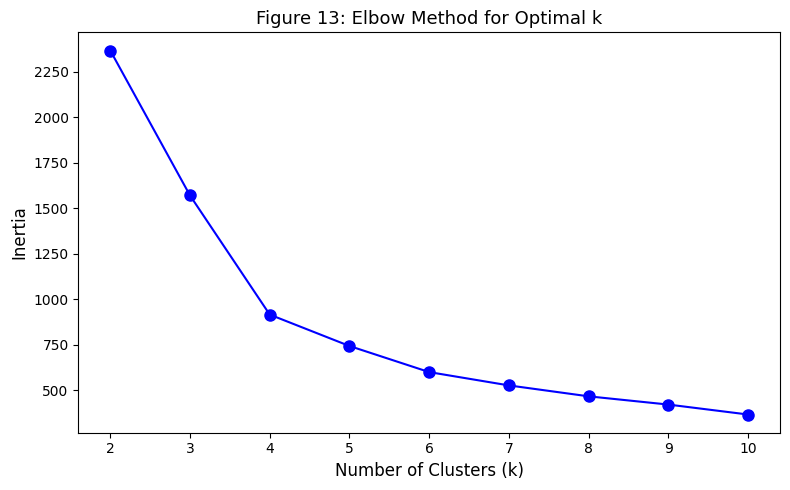

In [39]:
from sklearn.cluster import KMeans

# Elbow method for optimal k
cluster_features = ['log_pv', 'CTR', 'log_creatives_per_item', 'dow']
X_clust    = df_feat[cluster_features].copy()
X_clust_sc = StandardScaler().fit_transform(X_clust)

inertias = []
k_range  = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_clust_sc)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, 'bo-', markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia', fontsize=12)
plt.title('Figure 13: Elbow Method for Optimal k', fontsize=13)
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

PCA explained variance: 71.3%


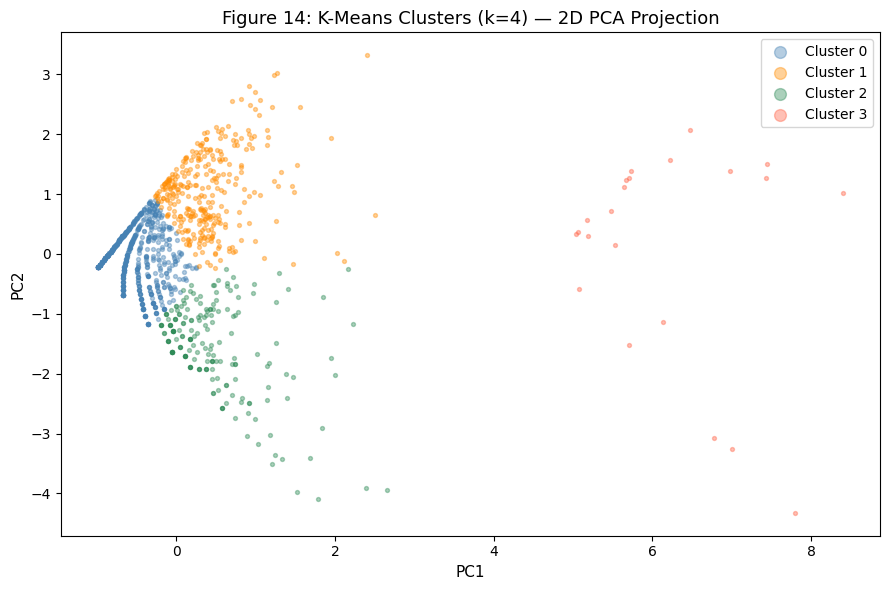


=== Cluster Profiles ===


pv              clk            CTR          \
              mean median      mean median    mean  median   
cluster                                                      
0          34.4339   24.0    1.9459    1.0  0.0605  0.0367   
1        1381.6913  291.0  206.1254   29.0  0.1036  0.0944   
2          56.8281   20.5   25.1615    8.0  0.3776  0.3305   
3        1376.0455   68.0  492.5909    4.5  0.2126  0.0871   

        log_creatives_per_item          
                          mean  median  
cluster                                 
0                       0.6931  0.6931  
1                       0.6931  0.6931  
2                       0.6931  0.6931  
3                       1.0986  1.0986

In [41]:
from sklearn.decomposition import PCA

# Fit K-Means with optimal k
K_OPT = 4
km_final = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
df_feat['cluster'] = km_final.fit_predict(X_clust_sc)

# 2D PCA projection for visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_clust_sc)
print(f'PCA explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%')

plt.figure(figsize=(9, 6))
colors = ['steelblue', 'darkorange', 'seagreen', 'tomato']
for c in range(K_OPT):
    mask = df_feat['cluster'] == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[c], label=f'Cluster {c}', alpha=0.4, s=8)
plt.xlabel('PC1', fontsize=11)
plt.ylabel('PC2', fontsize=11)
plt.title(f'Figure 14: K-Means Clusters (k={K_OPT}) \u2014 2D PCA Projection', fontsize=13)
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

print('\n=== Cluster Profiles ===')
display(
    df_feat.groupby('cluster')[['pv', 'clk', 'CTR', 'log_creatives_per_item']]
    .agg(['mean', 'median']).round(4)
)

In [43]:
from sklearn.model_selection import KFold, cross_val_score

# 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Regression CV
cv_rmse = -cross_val_score(best_xgb_reg, X, y_reg,
                            cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
cv_r2   =  cross_val_score(best_xgb_reg, X, y_reg,
                            cv=kf, scoring='r2', n_jobs=-1)
print('=== XGBoost Regressor --- 5-Fold CV ===')
print(f'  RMSE: {cv_rmse.mean():.4f} +/- {cv_rmse.std():.4f}')
print(f'  R2  : {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}')

# Classification CV
cv_auc = cross_val_score(best_xgb_clf, X, y_clf,
                          cv=kf, scoring='roc_auc', n_jobs=-1)
cv_f1  = cross_val_score(best_xgb_clf, X, y_clf,
                          cv=kf, scoring='f1', n_jobs=-1)
print('\n=== XGBoost Classifier --- 5-Fold CV ===')
print(f'  ROC-AUC: {cv_auc.mean():.4f} +/- {cv_auc.std():.4f}')
print(f'  F1-Score: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}')

=== XGBoost Regressor --- 5-Fold CV ===
  RMSE: 0.0274 +/- 0.0108
  R2  : 0.9607 +/- 0.0287

=== XGBoost Classifier --- 5-Fold CV ===
  ROC-AUC: 0.9985 +/- 0.0021
  F1-Score: 0.9924 +/- 0.0030


In [44]:
# Final Model Comparison Summary
print('=' * 55)
print('REGRESSION MODEL SUMMARY')
print('=' * 55)
display(pd.DataFrame(reg_results).T.round(4))

print()
print('=' * 55)
print('CLASSIFICATION MODEL SUMMARY')
print('=' * 55)
display(pd.DataFrame(clf_results).T.round(4))

print()
print('FINAL MODEL: XGBoost (Tuned)')
print('Justification: XGBoost consistently outperforms Linear Regression')
print('and Random Forest on both tasks. Its gradient boosting framework')
print('handles non-linear feature interactions and skewed ad data better.')
print('5-fold cross-validation confirms stable, low-variance generalization.')

REGRESSION MODEL SUMMARY


,MAE,RMSE,R2
Linear Regression,0.0456,0.0724,0.7560
Random Forest,0.0019,0.0106,0.9948
XGBoost,0.0052,0.0149,0.9897
XGBoost (Tuned),0.0041,0.0097,0.9956



CLASSIFICATION MODEL SUMMARY


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9791,0.9836,0.9756,0.9796,0.9992
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
XGBoost,0.9916,1.0000,0.9837,0.9918,0.9998
XGBoost (Tuned),0.9958,1.0000,0.9919,0.9959,0.9994



FINAL MODEL: XGBoost (Tuned)
Justification: XGBoost consistently outperforms Linear Regression
and Random Forest on both tasks. Its gradient boosting framework
handles non-linear feature interactions and skewed ad data better.
5-fold cross-validation confirms stable, low-variance generalization.
